# Synthetic data model

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx


## simplified model possibilities

Socioeconomic circumstances ──► Low-allergy formula prescription
          │                                  │
          │                                  ▼
          └──────────────────────────► Dental GA by age 6

Cow's milk allergy ─────────────► Low-allergy formula prescription
          │
          └──────────────────────────► Dental GA by age 6



EXPOSURE: formula_prescription

OUTCOME: dental_ga

POSSIBLE CONFOUNDERS: socioeconomic disadvantage and milk_allergy (alternative routes which might make children receiving the formula systematically different from those who don't )

socioeconomic_disadvantage ──► formula_prescription

socioeconomic_disadvantage ──► dental_ga

milk_allergy ─────────────────► formula_prescription

milk_allergy ─────────────────► dental_ga

formula_prescription ─────────► dental_ga

### in case there's a push towards over-prescribing

Practice prescribing tendency ──► formula_prescription

Area deprivation ──► practice_prescribing_tendency

Area deprivation ──► dental_ga




## synthetic data (simple version)

one row per child with these columns

 - child_id
 - socioeconomic_disadvantage
 - milk_allergy
 - formula_prescription
 - dental_ga

 with every value except ID binary (0=no, 1=yes)

 1. generate socio disadvantage and milk allergy
 2. make formula_prescription MORE LIKELY if milk_allergy and a little more likely for socio disad
 3. make GA more likely for socio disad
 4. add small causal effect of formula prescription on dental GA (ie creating what we're looking for here)

In [12]:
rng = np.random.default_rng(42)

n_children = 5_000

df = pd.DataFrame({
    "child_id": np.arange(1, n_children + 1),
    "socioeconomic_disadvantage": rng.binomial(1, 0.40, n_children),
    "milk_allergy": rng.binomial(1, 0.10, n_children),
})

formula_log_odds = (
    -3.0
    + 0.7 * df["socioeconomic_disadvantage"]
    + 2.5 * df["milk_allergy"]
)

formula_probability = 1 / (1 + np.exp(-formula_log_odds))

df["formula_prescription"] = rng.binomial(
    1,
    formula_probability,
)

dental_ga_log_odds = (
    -3.5
    + 1.0 * df["socioeconomic_disadvantage"]
    + 0.3 * df["milk_allergy"]
    + 0.5 * df["formula_prescription"]
)

dental_ga_probability = 1 / (1 + np.exp(-dental_ga_log_odds))

df["dental_ga"] = rng.binomial(
    1,
    dental_ga_probability,
)

df.tail()

,child_id,socioeconomic_disadvantage,milk_allergy,formula_prescription,dental_ga
4995,4996,0,0,0,0
4996,4997,0,0,0,0
4997,4998,0,0,0,0
4998,4999,0,0,0,0
4999,5000,1,0,0,0


### Inspect data

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   child_id                    5000 non-null   int64
 1   socioeconomic_disadvantage  5000 non-null   int64
 2   milk_allergy                5000 non-null   int64
 3   formula_prescription        5000 non-null   int64
 4   dental_ga                   5000 non-null   int64
dtypes: int64(5)
memory usage: 195.4 KB


In [14]:
df.describe()

,child_id,socioeconomic_disadvantage,milk_allergy,formula_prescription,dental_ga
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,0.390200,0.098400,0.100200,0.054800
std,1443.520003,0.487844,0.297885,0.300297,0.227612
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,1250.750000,0.000000,0.000000,0.000000,0.000000
50%,2500.500000,0.000000,0.000000,0.000000,0.000000
75%,3750.250000,1.000000,0.000000,0.000000,0.000000
max,5000.000000,1.000000,1.000000,1.000000,1.000000


In [15]:
# the mean gives the proportion of children with each characrteristic (since the variables are 0 or 1)
df.mean(numeric_only=True)

child_id                      2500.5000
socioeconomic_disadvantage       0.3902
milk_allergy                     0.0984
formula_prescription             0.1002
dental_ga                        0.0548
dtype: float64

### check relationships look sensible

In [16]:
# numbers
pd.crosstab(
    df["formula_prescription"],
    df["dental_ga"],
    margins=True
)

dental_ga,0,1,All
formula_prescription,,,
0,4281,218,4499
1,445,56,501
All,4726,274,5000


In [17]:
# children with milk allergy are prescribed formula much more often
pd.crosstab(
    df["milk_allergy"],
    df["formula_prescription"],
    normalize="index"
)

formula_prescription,0,1
milk_allergy,,
0,0.939885,0.060115
1,0.532520,0.467480


In [18]:
# higher dental GA rates among disadvantaged children
pd.crosstab(
    df["socioeconomic_disadvantage"],
    df["dental_ga"],
    normalize="index"
)

dental_ga,0,1
socioeconomic_disadvantage,,
0,0.966874,0.033126
1,0.911328,0.088672


# Draw the initial project DAG

This DAG represents our assumptions about how low-allergy formula prescribing
and dental general anaesthetic may be causally related.

Practice prescribing tendency may include clinician preference, local guidance
and exposure to pharmaceutical promotion. It is included in the DAG even
though it is not currently represented in the synthetic dataset.

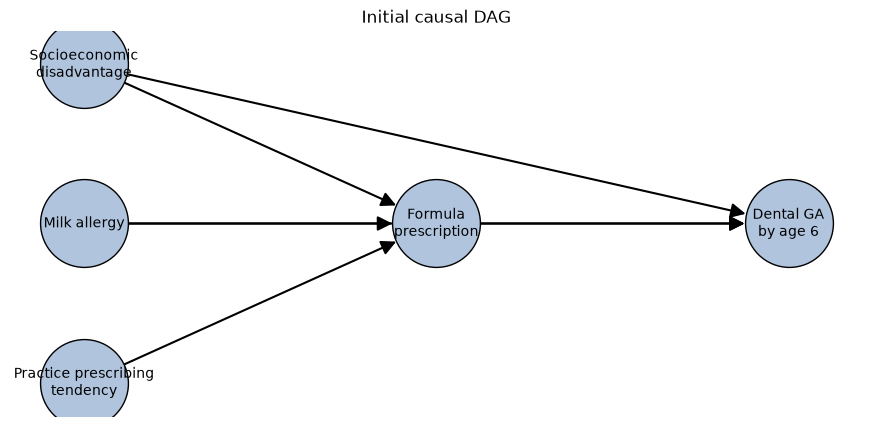

In [26]:

dag = nx.DiGraph()

dag.add_edges_from([
    ("Socioeconomic\ndisadvantage", "Formula\nprescription"),
    ("Socioeconomic\ndisadvantage", "Dental GA\nby age 6"),
    ("Milk allergy", "Formula\nprescription"),
    ("Milk allergy", "Dental GA\nby age 6"),
    ("Practice prescribing\ntendency", "Formula\nprescription"),
    ("Formula\nprescription", "Dental GA\nby age 6"),
])

positions = {
    "Socioeconomic\ndisadvantage": (0, 2),
    "Milk allergy": (0, 1),
    "Practice prescribing\ntendency": (0, 0),
    "Formula\nprescription": (2, 1),
    "Dental GA\nby age 6": (4, 1),
}

plt.figure(figsize=(11, 5))

nx.draw_networkx(
    dag,
    pos=positions,
    node_size=4000,
    font_size=10,
    arrowsize=22,
    width=1.5,
    node_color="lightsteelblue",   # or "lightblue", "aliceblue", "#DCEEFF"
    edgecolors="black",
)

plt.title("Initial causal DAG")
plt.axis("off")
plt.show()

## Next step: use the DAG to turn the research question into a plan for analysis

1. Decide what each node means
 - define EXPOSURE: at least one low-allergy formula prescription, or perhaps amount/duration prescribed
 - define OUTCOME: dental general anaesthetic by age six
 - define Milk allergy: confirmed diagnosis, suspected allergy, or symptoms
 - define Socioeconomic disadvantage: child-, household- or area-level measure
 - define Practice prescribing tendency: something measurable, such as the prescribing rate of the GP practice

2. Are arrows plausible?
 - for every arrow, write a short justification
 eg Socioeconomic disadvantage → formula prescription: why?
    
    Socioeconomic disadvantage → dental GA: why?

    Milk allergy → dental GA: if true, is it direct or does it operate through diet, healthacare use or another variable?

3. Identify missing variables
 - what else might affect prescribing and dental outcomes?

 Possibilities
 - child age and sex
 - ethnicity
 - maternal education
 - household deprivation
 - feeding difficulties
 - reflux or gastrointestinal symptoms
 - healthcare-seeking behaviour
 - antibiotic use
 - sugar intake after infancy
 - oral-health behaviour
 - access to dental care
 - GP practice
 - calendar year
 - local prescribing policy

 4. Use DAG to decide what to adjust for
  - identify variables that block non-causal paths between exposure and outcome.

  eg these 2 paths create confounding

  formula_prescription ← socioeconomic_disadvantage → dental_ga

  formula_prescription ← milk_allergy → dental_ga

  so the DAG suggests adjustment for socioeconomic_disadvantage and milk_allergy but NOT for practice_prescribing_tendency, because it only causes prescribing and does not also cause the outcome.

  5. Match each node to real data

  | DAG variable               | Possible data source             | Definition needed                      | Available? |
| -------------------------- | -------------------------------- | -------------------------------------- | ---------- |
| Formula prescription       | Primary care prescribing records | At least one prescription before age 1 | To confirm |
| Dental GA                  | Linked dental GA records         | Any GA before sixth birthday           | Available  |
| Milk allergy               | Diagnosis or clinical codes      | Confirmed or suspected allergy         | To confirm |
| Socioeconomic disadvantage | Postcode or household data       | IMD quintile or another measure        | Likely     |
| GP practice                | Primary care records             | Registered practice at prescribing     | To confirm |


